# Draft simulation results

Each of the six draft strategies drafted individually against 11 human-like opponents, who use a naive recency strategy with their own random disagreement (10%) added. Each strategy played 240 leagues in each of 2023-24, 2024-25, and 2025-26. Every seat was used equally (20 drafts for each of the 12 possible seats = 240).

## Key Findings

1. Using more than just last season's points matters the most. All strategies outperform it.
2. The base ML model has the best average score, but advantage depends on the season.
3. VORP does not appear to consistently help.
4. Drafting to minimize risk costs points. It performs worse than the base ML strategy in all 3 seasons.
5. Draft position matters, mostly at the very top.

## Methodology History

Several ways of testing the strategies against each other led to the current method:

1. Head-to-head: 12 teams in the draft, with each of the six strategies being used by two of the 12 teams. This resulted in naive recency coming out on top due to a crowding effect. Since 8 of the 12 teams were based on the model and drafted similarly to each other, players that the model underrated were drafted by the naive teams without opposition. The issue with this method was a lack of independence in the test method.
2. One team with a strategy vs 11 naive recency teams: One team has one of the six strategies, and the other 11 draft based on last season's points. Each strategy is run for each position in the draft for each year (repeated runs with the same position would produce identical results). This was a bit better, with all strategies beating the naive recency and the 3-season average was the best strategy. However, the two problems with this method is that it is fundamentally narrow (12 draft positions for each season x 3 seasons = only 36 drafts per team) and has a lack of randomness (the naive recency teams pick the exact same way each time and as each other). The second problem also has a crowding effect in the opposite way as the first method (the one strategy team always gets players that naive recency overlooks).
3. **Final method -  same 1-vs-11 setup, but each opponent has its own random noise**: This fixed the two problems with the previous method, and is what is used as the final method of choice.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))   # make the project root importable

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import config
from src.simulate import load_results, summarize

sns.set_theme(style="whitegrid")
results = load_results()
print(f"{len(results):,} results: {results['SEASON'].nunique()} seasons, "
      f"{results['STRATEGY'].nunique()} strategies, {results['DRAFT'].max()} leagues each")

4,320 results: 3 seasons, 6 strategies, 240 leagues each


## Overall results

In [2]:
finish = summarize(results, "FINISH").sort_values("ALL SEASONS")
edge = summarize(results, "EDGE_PCT").sort_values("ALL SEASONS", ascending=False)
print("Average finish (1 = best of 12):")
display(finish.round(2))
print("Points above the field's average team (%):")
display(edge.round(1))

Average finish (1 = best of 12):


SEASON,2023-24,2024-25,2025-26,ALL SEASONS
STRATEGY,,,,
best_available,1.52,2.70,1.02,1.74
naive_long_term,1.93,1.81,1.82,1.85
vorp,2.05,2.70,1.02,1.92
ceiling,1.85,3.01,1.03,1.97
floor,3.00,3.01,1.18,2.40
naive_recency,4.05,4.77,6.15,4.99


Points above the field's average team (%):


SEASON,2023-24,2024-25,2025-26,ALL SEASONS
STRATEGY,,,,
best_available,15.9,11.6,39.8,22.4
vorp,12.0,11.8,40.9,21.5
ceiling,13.4,10.9,38.3,20.9
naive_long_term,15.1,15.1,22.4,17.5
floor,8.3,9.9,29.2,15.8
naive_recency,7.2,5.4,1.1,4.6


## Sequential Strategy Comparisons

Each comparison changes one thing between two strategies. Because both faced the same opponents in every league, the difference in each league isolates the effect of that one change. The range is a 95% confidence interval for the average difference within each season.

In [3]:
COMPARISONS = [
    ("naive_long_term", "naive_recency", "More history: 3-season average vs. last season"),
    ("best_available", "naive_long_term", "Machine learning: model vs. 3-season average"),
    ("vorp", "best_available", "Positional scarcity: VORP vs. raw ranking"),
    ("floor", "vorp", "Risk-averse: floor vs. middle"),
    ("ceiling", "vorp", "Upside: ceiling vs. middle"),
]

edges = results.pivot_table(index=["SEASON", "DRAFT"], columns="STRATEGY", values="EDGE_PCT")
rows = []
for strategy, baseline, question in COMPARISONS:
    difference = edges[strategy] - edges[baseline]
    for season, values in difference.groupby(level="SEASON"):
        margin = 1.96 * values.std() / np.sqrt(len(values))
        rows.append({
            "Comparison": question,
            "SEASON": season,
            "Difference": values.mean(),
            "Low": values.mean() - margin,
            "High": values.mean() + margin,
        })
paired = pd.DataFrame(rows)
paired["Clear?"] = np.where(paired["Low"] > 0, "better", np.where(paired["High"] < 0, "worse", "unclear"))
paired.round(1)

,Comparison,SEASON,Difference,Low,High,Clear?
0,More history: 3-season average vs. last season,2023-24,7.9,6.8,9.0,better
1,More history: 3-season average vs. last season,2024-25,9.7,8.5,10.9,better
2,More history: 3-season average vs. last season,2025-26,21.3,19.6,22.9,better
3,Machine learning: model vs. 3-season average,2023-24,0.8,-0.3,1.8,unclear
4,Machine learning: model vs. 3-season average,2024-25,-3.5,-4.6,-2.4,worse
5,Machine learning: model vs. 3-season average,2025-26,17.4,16.0,18.8,better
6,Positional scarcity: VORP vs. raw ranking,2023-24,-3.8,-4.6,-3.1,worse
7,Positional scarcity: VORP vs. raw ranking,2024-25,0.1,-0.1,0.3,unclear
8,Positional scarcity: VORP vs. raw ranking,2025-26,1.1,0.8,1.4,better
9,Risk-averse: floor vs. middle,2023-24,-3.7,-4.3,-3.1,worse


## Charts

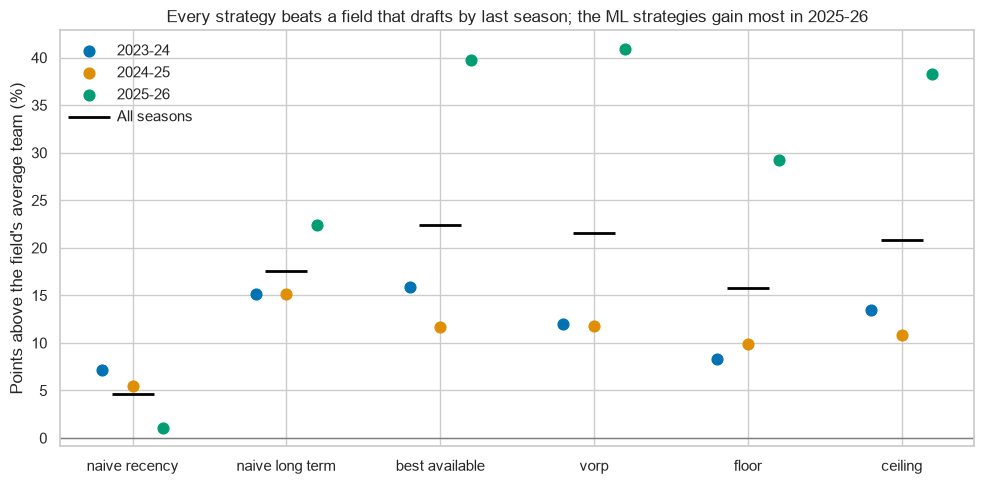

In [4]:
SEASON_COLORS = dict(zip(config.BACKTEST_SEASONS, sns.color_palette("colorblind", len(config.BACKTEST_SEASONS))))
strategy_order = list(config.STRATEGIES)
edge_by_season = results.groupby(["STRATEGY", "SEASON"])["EDGE_PCT"].mean().unstack()
overall = results.groupby("STRATEGY")["EDGE_PCT"].mean()

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(strategy_order))
for offset, season in zip([-0.2, 0, 0.2], config.BACKTEST_SEASONS):
    ax.scatter(x + offset, edge_by_season.loc[strategy_order, season], s=60,
               color=SEASON_COLORS[season], label=season, zorder=3)
ax.scatter(x, overall.loc[strategy_order], marker="_", s=900, color="black", linewidths=2,
           label="All seasons", zorder=4)
ax.axhline(0, color="gray", linewidth=1)
ax.set_xticks(x, [name.replace("_", " ") for name in strategy_order])
ax.set_ylabel("Points above the field's average team (%)")
ax.set_title("Every strategy beats a field that drafts by last season; the ML strategies gain most in 2025-26")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(config.PROJECT_ROOT / "outputs" / "edge_by_strategy.png", dpi=150, bbox_inches="tight")
plt.show()

All strategies score more points than the field in every season with the best available ML strategy, VORP ML strategy, and ceiling ML strategy scoring the most points on average. Also, as told by the great performances by all four ML strategies and poor performance by the naive recency strategy in 2025-2026, the prior year's numbers were a worse indicator than usual of the current year.

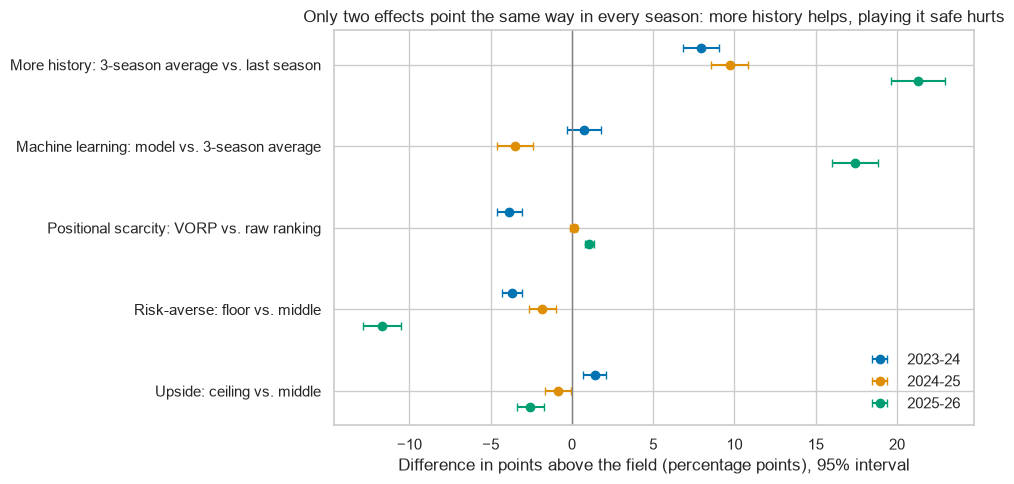

In [5]:
questions = [question for _, _, question in COMPARISONS]

fig, ax = plt.subplots(figsize=(10, 5))
for offset, season in zip([-0.2, 0, 0.2], config.BACKTEST_SEASONS):
    season_rows = paired[paired["SEASON"] == season].set_index("Comparison").loc[questions]
    y = np.arange(len(questions)) + offset
    ax.errorbar(season_rows["Difference"], y,
                xerr=[season_rows["Difference"] - season_rows["Low"], season_rows["High"] - season_rows["Difference"]],
                fmt="o", color=SEASON_COLORS[season], capsize=3, label=season)
ax.axvline(0, color="gray", linewidth=1)
ax.set_yticks(np.arange(len(questions)), questions)
ax.invert_yaxis()
ax.set_xlabel("Difference in points above the field (percentage points), 95% interval")
ax.set_title("Only two effects point the same way in every season: more history helps, playing it safe hurts")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(config.PROJECT_ROOT / "outputs" / "paired_comparisons.png", dpi=150, bbox_inches="tight")
plt.show()

The 3 season average is a clear improvement over the naive recency, and the raw ranking base model has a better average result than the 3 season average. After this, it seems as though no model is able to outperform the previous, leading to the conclusion that the raw ranking base model is the best of the six on average.

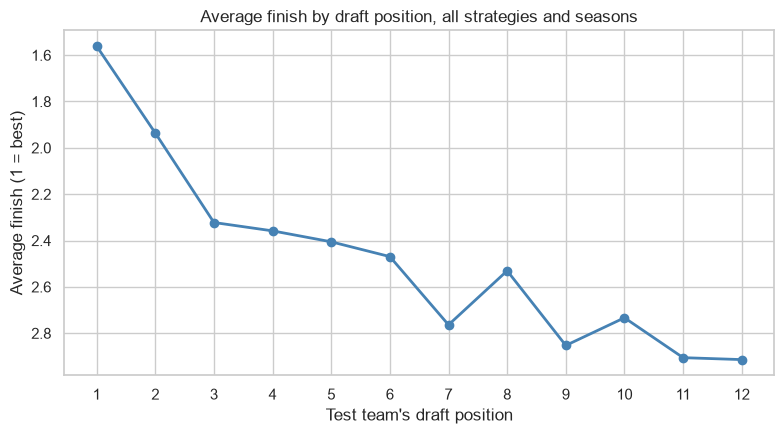

In [6]:
by_position = results.groupby("DRAFT_POSITION")["FINISH"].mean()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(by_position.index, by_position.values, marker="o", color="steelblue", linewidth=2)
ax.set_xticks(range(1, config.NUM_TEAMS + 1))
ax.set_xlabel("Test team's draft position")
ax.set_ylabel("Average finish (1 = best)")
ax.invert_yaxis()
ax.set_title("Average finish by draft position, all strategies and seasons")
fig.tight_layout()
fig.savefig(config.PROJECT_ROOT / "outputs" / "finish_by_position.png", dpi=150, bbox_inches="tight")
plt.show()

There is a clear direct correlation between an earlier draft position and higher placing, with an overall downward trend and sequential downward movement from spots 1-7, 8-9, and 10-12. However, the biggest effect is at the very top between picks 1 and 3, with the difference between them being greater than the difference between 3 and 12.